# Chapter 5: The First Learning Neuron, Live Python Exercises (Solutions)

**ECUE 3.1.3: Neural Communication** &bull; CESI Bachelor AI (Year 2)

Reference solutions for the Chapter 5 exercises. Try the [exercise notebook](Chapter5_LiveExercises.ipynb) yourself before looking in here.

<div style="border-left: 4px solid #f59e0b; padding: 0.5em 1em; background: rgba(245,158,11,0.08);">
<b>Sanity check:</b> run the cell below. If it prints a NumPy version with no error, your environment is ready. If not, go back to <code>Chapter1_Setup.ipynb</code>.
</div>

In [2]:
import numpy as np

print("NumPy version:", np.__version__)
print("Environment OK ✔")

NumPy version: 2.5.4
Environment OK ✔


---

## Reminder: the McCulloch-Pitts Neuron

The perceptron keeps **exactly the same neuron** as Chapter 4. Run the cell below so `mp_neuron` is available in this notebook.

In [3]:
def mp_neuron(x, w, b):
    z = np.dot(w, x) + b       # weighted sum + bias (spatial summation)
    return 1 if z >= 0 else 0  # step function (all-or-nothing decision)

---

## Live Exercise: One Learning Step

Recall the perceptron learning rule:

$$w_i \leftarrow w_i + \eta\,(t - y)\,x_i \qquad\qquad b \leftarrow b + \eta\,(t - y)$$

where $e = t - y$ is the **error** (in the code: `e`) and $\eta$ is the **learning rate** (in the code: `eta`).

### Your turn

Write `perceptron_update(x, t, w, b, eta)` that:
1. computes the neuron's output `y` with `mp_neuron`,
2. computes the error `e = t - y`, then updates `w` and `b` with the rule above,
3. returns the new `w`, the new `b`, and `y` (the answer **before** the update).

In [4]:
def perceptron_update(x, t, w, b, eta=1.0):
    y = mp_neuron(x, w, b)
    e = t - y                    # the error: -1, 0 or +1
    w = w + eta * e * x          # only active inputs (x_i = 1) move
    b = b + eta * e              # the bias moves like a weight on a constant input 1
    return w, b, y

### Check it against your paper table

The cell below runs **epoch 1 on OR**, from $w_1 = w_2 = 0$, $b = 0$, $\eta = 1$, and prints one line per row. Compare every line with the table you filled in by hand.

In [5]:
X_or = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
T_or = np.array([0, 1, 1, 1])

w, b = np.zeros(2), 0.0
print(" x1 x2 | t | old w1 old w2 old b |  z | y |  e | new w1 new w2 new b")
print("-" * 70)
for x, t in zip(X_or, T_or):
    old_w, old_b = w, b
    z = np.dot(old_w, x) + old_b
    w, b, y = perceptron_update(x, t, w, b, eta=1.0)
    print(f"  {x[0]}  {x[1]} | {t} | {old_w[0]:6.1f} {old_w[1]:6.1f} {old_b:5.1f} | {z:2.0f} | {y} | {t - y:2d} | "
          f"{w[0]:6.1f} {w[1]:6.1f} {b:5.1f}")

 x1 x2 | t | old w1 old w2 old b |  z | y |  e | new w1 new w2 new b
----------------------------------------------------------------------
  0  0 | 0 |    0.0    0.0   0.0 |  0 | 1 | -1 |    0.0    0.0  -1.0
  0  1 | 1 |    0.0    0.0  -1.0 | -1 | 0 |  1 |    0.0    1.0   0.0
  1  0 | 1 |    0.0    1.0   0.0 |  0 | 1 |  0 |    0.0    1.0   0.0
  1  1 | 1 |    0.0    1.0   0.0 |  1 | 1 |  0 |    0.0    1.0   0.0


---

## Live Exercise: The Training Loop

```text
initialize w = 0, b = 0
repeat for each epoch:
    for each example (x, t):
        apply the perceptron rule
    if no mistakes in this epoch:
        stop
```

### Your turn

Write `train_perceptron(X, T, eta, n_epochs)` that runs the loop above, using your `perceptron_update`. It must return the learned `w` and `b`, and `mistakes`: a list with the **number of mistakes in each epoch**.

In [ ]:
def train_perceptron(X, T, eta=1.0, n_epochs=20):
    w, b = np.zeros(X.shape[1]), 0.0
    mistakes = []
    for epoch in range(n_epochs):
        fails = 0
        for x, t in zip(X, T):
            w, b, y = perceptron_update(x, t, w, b, eta)
            fails += int(y != t)
        mistakes.append(fails)
        if fails == 0:          # a full epoch without a mistake: nothing will move anymore
            break
    return w, b, mistakes

### Training OR, AND and NOT

Compare the learned weights with the ones you picked by hand in Chapter 4: AND $(1, 1, -1.5)$, OR $(1, 1, -0.5)$, NOT $(-1, 0.5)$.

**Before running**: do you expect the neuron to learn *exactly* these values?

In [ ]:
X_2 = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
X_1 = np.array([[0], [1]])

gates = {
    "OR":  (X_2, np.array([0, 1, 1, 1])),
    "AND": (X_2, np.array([0, 0, 0, 1])),
    "NOT": (X_1, np.array([1, 0])),
}

for name, (X, T) in gates.items():
    w, b, mistakes = train_perceptron(X, T)
    outputs = [mp_neuron(x, w, b) for x in X]
    print(f"{name:3s} | w = {w}, b = {b} | mistakes per epoch: {mistakes} | outputs: {outputs}, targets: {T.tolist()}")

### Solution

| Gate | By hand $(w, b)$ | Learned $(w, b)$ | Epochs |
|:---:|:---:|:---:|:---:|
| OR  | $(1, 1)$, $-0.5$ | $(1, 1)$, $-1$ | 4 |
| AND | $(1, 1)$, $-1.5$ | $(2, 1)$, $-3$ | 6 |
| NOT | $(-1)$, $0.5$ | $(-1)$, $0$ | 3 |

Starting from zero with $\eta = 1$, every update adds or subtracts whole numbers, so a bias of $-1.5$ is unreachable. The asymmetric AND solution $(2, 1)$ comes from the **order** of the rows. Many valid answers exist: learning finds **one** of them.

---

## Live Exercise: New Gates, Nobody Picks the Weights

In Chapter 4, **you** picked the weights of every gate. Now the rule does it. Three gates you have not trained yet:

| Gate | Inputs | Output is 1 when... |
|:---:|:---:|:---|
| NAND | 2 | NOT (x1 AND x2): every case except (1, 1) |
| NOR | 2 | NOT (x1 OR x2): only (0, 0) |
| MAJORITY | 3 | at least 2 of the 3 inputs are 1 |

Careful: **NOR is not NOT**. NOT flips **one** input; NOR first combines **two** inputs with OR, then flips the result. Feed NOR the same input twice, $x_1 = x_2 = x$, and it behaves exactly like NOT.

### Your turn

1. **On paper first**: find weights and a bias for MAJORITY by hand.
2. Write the targets of the three gates, train them with `train_perceptron`, and check the outputs.
3. Compare the learned MAJORITY neuron with yours. Does it treat the three inputs the same way? Why does that make sense?
4. Compare the learned NOR with the NOT learned in the previous exercise. What do you notice?

In [8]:
X_3 = np.array([[a, b, c] for a in (0, 1) for b in (0, 1) for c in (0, 1)])   # the 8 combinations of 3 inputs

new_gates = {
    "NAND":     (X_2, np.array([1, 1, 1, 0])),
    "NOR":      (X_2, np.array([1, 0, 0, 0])),
    "MAJORITY": (X_3, np.array([0, 0, 0, 1, 0, 1, 1, 1])),
}

for name, (X, T) in new_gates.items():
    w, b, mistakes = train_perceptron(X, T)
    outputs = [mp_neuron(x, w, b) for x in X]
    print(f"{name:8s} | w = {w}, b = {b} | mistakes per epoch: {mistakes} | outputs: {outputs}, targets: {T.tolist()}")

NAND     | w = [-2. -1.], b = 2.0 | mistakes per epoch: [1, 3, 3, 2, 1, 0] | outputs: [1, 1, 1, 0], targets: [1, 1, 1, 0]
NOR      | w = [-1. -1.], b = 0.0 | mistakes per epoch: [1, 2, 1, 0] | outputs: [1, 0, 0, 0], targets: [1, 0, 0, 0]
MAJORITY | w = [1. 1. 1.], b = -2.0 | mistakes per epoch: [4, 3, 1, 0] | outputs: [0, 0, 0, 1, 0, 1, 1, 1], targets: [0, 0, 0, 1, 0, 1, 1, 1]


### Solution

| Gate | Learned $w$ | Learned $b$ | Epochs |
|:---:|:---:|:---:|:---:|
| NAND | $(-2, -1)$ | $2$ | 6 |
| NOR | $(-1, -1)$ | $0$ | 4 |
| MAJORITY | $(1, 1, 1)$ | $-2$ | 4 |

- **NAND and NOR** are AND and OR with **inhibitory** weights: the neuron fires by default ($b \geq 0$) and the inputs silence it.
- **NOR** $(-1, -1)$, $0$ is the learned **NOT** $(-1)$, $0$ with a second, identical inhibitory input: NOR with one input is NOT, and the rule found it by itself.
- **MAJORITY** learns **three equal weights** and a bias of $-2$: every input casts one vote, and the neuron fires from 2 votes. A by-hand answer such as $(1, 1, 1)$ and $-1.5$ is just as valid. The three inputs play the same role in the truth table, so nothing pushes one weight above the others. As a neuron, this is **spatial summation**: one active synapse is not enough, two together reach the threshold.
- Why NAND? Any logic circuit, a whole processor included, can be built with **NAND gates only**. Keep that in mind for Chapter 6: what one neuron cannot do, several neurons together might.

---

## Think: Can One Neuron Build Every Gate?

In Chapter 4, no MCP neuron could reproduce XOR. What about the new gates? **Discuss first, then check.**

1. Can a single MCP neuron reproduce NAND, NOR and MAJORITY? How do you know, **without** searching for weights?
2. With 2 inputs, a truth table has 4 rows, so there are $2^4 = 16$ possible gates. How many can **one** neuron reproduce?
3. Which ones are **impossible**, like XOR?

### Check it

Reuse the grid search of Chapter 4: for each of the 16 truth tables below, look for a triple $(w_1, w_2, b)$ on a grid that reproduces it. The cell prints the full matrix: one line per gate, its 4 outputs, and whether one neuron can build it.

In [9]:
grid = np.arange(-2, 2.01, 0.5)

# the 16 gates of two inputs: targets for (0, 0), (0, 1), (1, 0), (1, 1)
gates_16 = {
    "FALSE (always 0)":   [0, 0, 0, 0],
    "AND":                [0, 0, 0, 1],
    "x1 AND NOT x2":      [0, 0, 1, 0],
    "x1 (copy)":          [0, 0, 1, 1],
    "NOT x1 AND x2":      [0, 1, 0, 0],
    "x2 (copy)":          [0, 1, 0, 1],
    "XOR":                [0, 1, 1, 0],
    "OR":                 [0, 1, 1, 1],
    "NOR":                [1, 0, 0, 0],
    "XNOR":               [1, 0, 0, 1],
    "NOT x2":             [1, 0, 1, 0],
    "x1 OR NOT x2":       [1, 0, 1, 1],
    "NOT x1":             [1, 1, 0, 0],
    "NOT x1 OR x2":       [1, 1, 0, 1],
    "NAND":               [1, 1, 1, 0],
    "TRUE (always 1)":    [1, 1, 1, 1],
}

print(f"{'gate':18s} | (0,0) (0,1) (1,0) (1,1) | 1 neuron?")
print("-" * 54)
n_possible = 0
for name, T in gates_16.items():
    found = False
    for w1 in grid:
        for w2 in grid:
            for b in grid:
                if [mp_neuron(x, [w1, w2], b) for x in X_2] == T:
                    found = True
    n_possible += int(found)
    print(f"{name:18s} |   {T[0]}     {T[1]}     {T[2]}     {T[3]}   | {'yes' if found else 'NO'}")

print(n_possible, "gates out of 16 fit in one neuron")
print(x, [w1, w2], b)

gate               | (0,0) (0,1) (1,0) (1,1) | 1 neuron?
------------------------------------------------------
FALSE (always 0)   |   0     0     0     0   | yes
AND                |   0     0     0     1   | yes
x1 AND NOT x2      |   0     0     1     0   | yes
x1 (copy)          |   0     0     1     1   | yes
NOT x1 AND x2      |   0     1     0     0   | yes
x2 (copy)          |   0     1     0     1   | yes
XOR                |   0     1     1     0   | NO
OR                 |   0     1     1     1   | yes
NOR                |   1     0     0     0   | yes
XNOR               |   1     0     0     1   | NO
NOT x2             |   1     0     1     0   | yes
x1 OR NOT x2       |   1     0     1     1   | yes
NOT x1             |   1     1     0     0   | yes
NOT x1 OR x2       |   1     1     0     1   | yes
NAND               |   1     1     1     0   | yes
TRUE (always 1)    |   1     1     1     1   | yes
14 gates out of 16 fit in one neuron
[1 1] [np.float64(2.0), np.float64(2.

### Solution

1. **Yes** for NAND, NOR and MAJORITY, and you know it without searching: `train_perceptron` stopped on an epoch without a mistake, so the weights it returned reproduce the gate.
2. **14 gates out of 16** are possible:

| Gate | $(0,0)$ | $(0,1)$ | $(1,0)$ | $(1,1)$ | 1 neuron? |
|:---|:---:|:---:|:---:|:---:|:---:|
| FALSE *(always 0)* | 0 | 0 | 0 | 0 | yes |
| AND | 0 | 0 | 0 | 1 | yes |
| $x_1$ AND NOT $x_2$ | 0 | 0 | 1 | 0 | yes |
| $x_1$ *(copy)* | 0 | 0 | 1 | 1 | yes |
| NOT $x_1$ AND $x_2$ | 0 | 1 | 0 | 0 | yes |
| $x_2$ *(copy)* | 0 | 1 | 0 | 1 | yes |
| **XOR** | **0** | **1** | **1** | **0** | **no** |
| OR | 0 | 1 | 1 | 1 | yes |
| NOR | 1 | 0 | 0 | 0 | yes |
| **XNOR** | **1** | **0** | **0** | **1** | **no** |
| NOT $x_2$ | 1 | 0 | 1 | 0 | yes |
| $x_1$ OR NOT $x_2$ | 1 | 0 | 1 | 1 | yes |
| NOT $x_1$ | 1 | 1 | 0 | 0 | yes |
| NOT $x_1$ OR $x_2$ | 1 | 1 | 0 | 1 | yes |
| NAND | 1 | 1 | 1 | 0 | yes |
| TRUE *(always 1)* | 1 | 1 | 1 | 1 | yes |

3. The 2 impossible ones are `[0, 1, 1, 0]`, **XOR**, and `[1, 0, 0, 1]`, **XNOR** (XOR flipped: 1 when both inputs are equal). With 3 inputs, **PARITY** (1 when an odd number of inputs is on) is impossible as well.

AND, OR, MAJORITY only depend on **how many** inputs are on: a weighted sum is good at counting. XOR and XNOR ask whether the inputs **agree**: $(0, 0)$ and $(1, 1)$ give the smallest and the largest sums, yet they must give the same answer. Why this is impossible for one neuron, and how to get around it, is Chapter 6.

---

## Live Exercise: The Perceptron as a Class

Until now, the state of the neuron (`w`, `b`, `mistakes`) travels between functions as separate variables. A **class** keeps the state and the functions that use it together, in one object:

- **attributes** (`self.w`, `self.b`, `self.mistakes_`): the state of *this* neuron, kept from one call to the next;
- **methods** (`predict`, `fit`): functions that read or change that state. `self` is the neuron itself.

`__init__` runs once, when the object is created: `p = Perceptron(n_features=2)`. Then `p.fit(X, T)` trains it, `p.predict(X)` decodes, and `p.w` reads its weights. This is the shape of the decoder you will write in Project 1.

Two upgrades on the way:

1. **Predict all the examples at once.** With one example per row of `X`, `X @ self.w + self.b` computes the weighted sum of **every row**: a vector of $z$, one per example. `(z >= 0).astype(int)` applies the step function to all of them.
2. **A random order.** `fit` visits the examples in a new random order at each epoch: `self.rng.permutation(len(X))` returns the indices `0, 1, ..., n - 1`, shuffled.

### Your turn

Complete `predict` and `fit`. `fit` does exactly what `train_perceptron` does (reuse `perceptron_update`), except the order of the examples. It returns `self`, so that you can write `Perceptron(2).fit(X, T)` in one line.

In [10]:
class Perceptron:
    def __init__(self, n_features, eta=1.0, epochs=20, seed=0):
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.eta = eta
        self.epochs = epochs
        self.rng = np.random.default_rng(seed)
        self.mistakes_ = []  # number of mistakes per epoch

    def predict(self, X):
        z = X @ self.w + self.b          # one weighted sum per row of X
        return (z >= 0).astype(int)      # step function on all of them

    def fit(self, X, T):
        for epoch in range(self.epochs):
            errors = 0
            for k in self.rng.permutation(len(X)):    # a new random order at each epoch
                self.w, self.b, y = perceptron_update(X[k], T[k], self.w, self.b, self.eta)
                errors += int(y != T[k])
            self.mistakes_.append(errors)
            if errors == 0:          # a full epoch without a mistake: nothing will move anymore
                break
        return self

### Check it on OR, AND and NOT

In [11]:
for name, (X, T) in gates.items():
    p = Perceptron(n_features=X.shape[1]).fit(X, T)
    print(f"{name:3s} | w = {p.w}, b = {p.b} | mistakes per epoch: {p.mistakes_} | "
          f"outputs: {p.predict(X).tolist()}, targets: {T.tolist()}")

OR  | w = [1. 1.], b = -1.0 | mistakes per epoch: [2, 1, 1, 1, 0] | outputs: [0, 1, 1, 1], targets: [0, 1, 1, 1]
AND | w = [1. 1.], b = -2.0 | mistakes per epoch: [2, 2, 1, 1, 1, 3, 0] | outputs: [0, 0, 0, 1], targets: [0, 0, 0, 1]
NOT | w = [-1.], b = 0.0 | mistakes per epoch: [1, 1, 0] | outputs: [1, 0], targets: [1, 0]


**Question**: compare with `train_perceptron` above. Are the outputs the same? The weights? The number of epochs? Why is visiting the examples in a random order a good habit?

### Solution

- **The outputs are the same**: every gate is learned, and `predict` gives the targets.
- **The weights and the number of epochs can differ** from `train_perceptron`. Here OR gets the same weights in 5 epochs instead of 4, and AND finds $(1, 1)$, $-2$ in 7 epochs instead of $(2, 1)$, $-3$ in 6: a symmetric solution, just as valid. The rule only moves on mistakes, and which example makes a mistake first depends on the order. Many weight vectors separate the same data, and the perceptron stops on the first one it reaches.
- **Why a random order?** In a fixed order (for example all the examples of one class first), the last updates of every epoch always push the weights the same way, and the result partly depends on the order of the data rather than on the data. On data that are not separable, a fixed order can also repeat the same sequence of mistakes forever. Shuffling at each epoch removes these artefacts. The `seed` keeps the run reproducible: the same seed gives the same shuffles, so the same weights.

---

## Live Exercise: One Problem, Many Solutions

The `seed` changes the order in which `fit` visits the examples. Does it change the answer?

### Your turn

1. Train a `Perceptron` on AND with each seed from 0 to 9. Print the learned `w`, `b`, and the number of epochs.
2. Keep each **different** solution in a list `solutions`, as a tuple `(w1, w2, b)`. How many are there? Do they all compute AND?
3. For each solution, print $z$ on the 4 inputs, and do the same with your hand-picked weights from Chapter 4, $(1, 1)$ and $-1.5$. Imagine a noisy input, `[0.9, 1]` instead of `[1, 1]`: which neuron would you trust?

In [12]:
T_and = np.array([0, 0, 0, 1])
solutions = []

for seed in range(10):
    p = Perceptron(n_features=2, seed=seed).fit(X_2, T_and)
    sol = (float(p.w[0]), float(p.w[1]), float(p.b))
    print(f"seed {seed} | w = {p.w}, b = {p.b} | epochs: {len(p.mistakes_)} | outputs: {p.predict(X_2).tolist()}")
    if sol not in solutions:
        solutions.append(sol)

print(len(solutions), "different solutions:", solutions)

seed 0 | w = [1. 1.], b = -2.0 | epochs: 7 | outputs: [0, 0, 0, 1]
seed 1 | w = [1. 1.], b = -2.0 | epochs: 4 | outputs: [0, 0, 0, 1]
seed 2 | w = [1. 2.], b = -3.0 | epochs: 9 | outputs: [0, 0, 0, 1]
seed 3 | w = [1. 1.], b = -2.0 | epochs: 7 | outputs: [0, 0, 0, 1]
seed 4 | w = [1. 1.], b = -2.0 | epochs: 4 | outputs: [0, 0, 0, 1]
seed 5 | w = [1. 1.], b = -2.0 | epochs: 6 | outputs: [0, 0, 0, 1]
seed 6 | w = [1. 2.], b = -3.0 | epochs: 8 | outputs: [0, 0, 0, 1]
seed 7 | w = [1. 1.], b = -2.0 | epochs: 6 | outputs: [0, 0, 0, 1]
seed 8 | w = [1. 2.], b = -3.0 | epochs: 9 | outputs: [0, 0, 0, 1]
seed 9 | w = [1. 2.], b = -3.0 | epochs: 7 | outputs: [0, 0, 0, 1]
2 different solutions: [(1.0, 1.0, -2.0), (1.0, 2.0, -3.0)]


In [13]:
for w1, w2, b in solutions + [(1, 1, -1.5)]:
    z = X_2 @ np.array([w1, w2]) + b
    print(f"w = ({w1}, {w2}), b = {b:5} | z on (0,0), (0,1), (1,0), (1,1): {z}")

print()
print("noisy input [0.9, 1]:")
for w1, w2, b in solutions + [(1, 1, -1.5)]:
    print(f"w = ({w1}, {w2}), b = {b:5} -> y =", mp_neuron(np.array([0.9, 1]), np.array([w1, w2]), b))

w = (1.0, 1.0), b =  -2.0 | z on (0,0), (0,1), (1,0), (1,1): [-2. -1. -1.  0.]
w = (1.0, 2.0), b =  -3.0 | z on (0,0), (0,1), (1,0), (1,1): [-3. -1. -2.  0.]
w = (1, 1), b =  -1.5 | z on (0,0), (0,1), (1,0), (1,1): [-1.5 -0.5 -0.5  0.5]

noisy input [0.9, 1]:
w = (1.0, 1.0), b =  -2.0 -> y = 0
w = (1.0, 2.0), b =  -3.0 -> y = 0
w = (1, 1), b =  -1.5 -> y = 1


### Solution

- **Two solutions** come out of the ten seeds: $(1, 1)$, $-2$ and $(1, 2)$, $-3$. Both compute AND perfectly on the 4 examples.
- Look at $z$ on $(1, 1)$: it is **exactly 0** for both learned neurons. The line passes **right on** an example. The rule stops at the first epoch without a mistake: it stops as soon as it is *right*, not when it is *safe*.
- With the noisy input `[0.9, 1]`, both learned neurons answer 0. The hand-picked neuron keeps a margin of 0.5 on every example (its $z$ is never closer to 0 than that), and still answers 1.
- On real recordings, every trial is a little noisy. Remember the borderline trial of Bonus 2, further down in this notebook: same cause. Finding the **safest** line, the one farthest from every example, is the idea behind later classifiers such as the support vector machine.

---

## And XOR?

The convergence theorem says the rule finds a solution **if one exists**. Run the cell below and look at the mistakes per epoch.

In [14]:
T_xor = np.array([0, 1, 1, 0])

w, b, mistakes = train_perceptron(X_2, T_xor, n_epochs=20)
print("mistakes per epoch:", mistakes)
print("final w =", w, ", b =", b)
print("outputs:", [mp_neuron(x, w, b) for x in X_2], "targets:", T_xor.tolist())

mistakes per epoch: [3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
final w = [-1.  0.] , b = 0.0
outputs: [1, 1, 0, 0] targets: [0, 1, 1, 0]


**Question**: does increasing `n_epochs` to 1000 help? Try it. Why do you think the rule never stops making mistakes? *(We answer this properly in Chapter 6.)*

In [15]:
w, b, mistakes = train_perceptron(X_2, T_xor, n_epochs=1000)
print("epochs run:", len(mistakes), "| mistakes in the last 10 epochs:", mistakes[-10:])

epochs run: 1000 | mistakes in the last 10 epochs: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


### Solution

The mistakes never reach 0, however many epochs you run: the rule keeps correcting, but there are **no** weights to converge to. The "if" of the convergence theorem is not satisfied.

---

## Chapter Bilan: Decode a Stimulus From Firing Rates

*Synthesis exercise, and a first taste of Project 1. No scaffolding this time.*

Three neurons were recorded over 8 trials. On each trial, one of two stimuli was shown: **A** (target `0`) or **B** (target `1`). Each input is a firing rate in Hz.

| Trial | $x_1$ *(Hz)* | $x_2$ *(Hz)* | $x_3$ *(Hz)* | Stimulus |
|:---:|:---:|:---:|:---:|:---:|
| 1 | 12 | 35 | 20 | A *(0)* |
| 2 | 8  | 40 | 25 | A *(0)* |
| 3 | 15 | 30 | 18 | A *(0)* |
| 4 | 10 | 38 | 22 | A *(0)* |
| 5 | 30 | 15 | 21 | B *(1)* |
| 6 | 35 | 10 | 19 | B *(1)* |
| 7 | 28 | 18 | 24 | B *(1)* |
| 8 | 33 | 12 | 20 | B *(1)* |

### Your turn

1. Train `train_perceptron` on these 8 trials.
2. Predict the stimulus for the 4 **new** trials in `X_new`, which the neuron has never seen.
3. **Evaluate** the decoder on these new trials: accuracy and confusion matrix.
4. Plot **two figures**: the mistakes per epoch, and the learned weights.
5. Look at the learned `w`: which neuron **matters most**, and which one **carries no information** about the stimulus?

In [16]:
X_train = np.array([[12, 35, 20], [8, 40, 25], [15, 30, 18], [10, 38, 22],
                    [30, 15, 21], [35, 10, 19], [28, 18, 24], [33, 12, 20]])
T_train = np.array([0, 0, 0, 0, 1, 1, 1, 1])

X_new = np.array([[11, 33, 23], [31, 14, 22], [14, 36, 19], [26, 20, 18]])
T_new = np.array([0, 1, 0, 1])   # true stimuli of the new trials: A, B, A, B

In [17]:
# Functional approach
w, b, mistakes = train_perceptron(X_train, T_train)
print("w =", w, ", b =", b, ", mistakes per epoch:", mistakes)

predictions = [mp_neuron(x, w, b) for x in X_new]
print("predictions:", predictions, "->", ["AB"[p] for p in predictions])

w = [ 18. -20.   1.] , b = 0.0 , mistakes per epoch: [2, 0]
predictions: [0, 1, 0, 1] -> ['A', 'B', 'A', 'B']


In [18]:
# Object approach
p = Perceptron(n_features=3, seed=42).fit(X_train, T_train)
print("w =", p.w, ", b =", p.b, ", mistakes per epoch:", p.mistakes_)

predictions = p.predict(X_new)
print("predictions:", predictions.tolist(), "->", ["AB"[k] for k in predictions])

w = [ 20. -23.  -1.] , b = 0.0 , mistakes per epoch: [2, 0]
predictions: [0, 1, 0, 1] -> ['A', 'B', 'A', 'B']


---

### Step 3: evaluate the decoder

The true stimuli of the 4 new trials are `T_new = [0, 1, 0, 1]`. Compute the **accuracy** on these test trials, and the **confusion matrix** (rows: true stimulus, columns: prediction). This is how both projects measure a decoder: always on trials it has never seen.

In [19]:
pred = np.array([mp_neuron(x, w, b) for x in X_new])
accuracy = np.mean(pred == T_new)

confusion = np.zeros((2, 2), dtype=int)
for t, p in zip(T_new, pred):
    confusion[t, p] += 1

print(f"test accuracy: {accuracy:.0%}")
print("confusion matrix (rows = true A, B; columns = predicted A, B):")
print(confusion)

test accuracy: 100%
confusion matrix (rows = true A, B; columns = predicted A, B):
[[2 0]
 [0 2]]


### Solution

100 % on 4 test trials, and a diagonal confusion matrix. With so few trials, one mistake would already cost 25 %: on real recordings, you want many more test trials.

### Step 4: two figures

A result is easier to read, and to defend in a report, with a figure. Plot side by side:
1. the **mistakes per epoch** (`mistakes`, returned by `train_perceptron`): does the training converge?
2. the **learned weights**, one bar per neuron (`plt.bar`): which ones are large, which ones are close to 0?

*Hint*: `fig, axes = plt.subplots(1, 2)`, as in Chapter 7, gives two plots side by side.

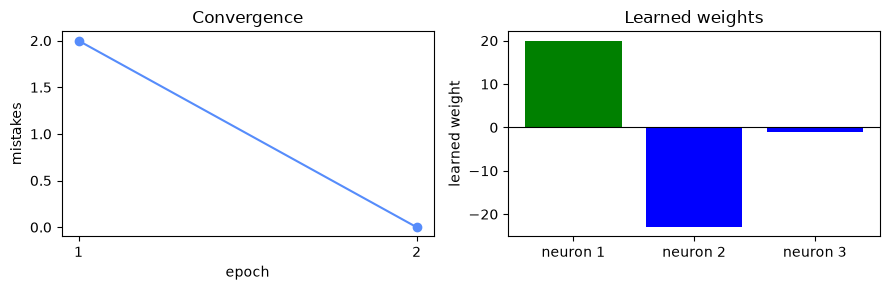

In [20]:
import matplotlib.pyplot as plt

p = Perceptron(n_features=3, seed=42).fit(X_train, T_train)

epochs = range(1, len(p.mistakes_) + 1)

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(epochs, p.mistakes_, marker="o")
axes[0].set_xticks(list(epochs))
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("mistakes")
axes[0].set_title("Convergence")

axes[1].bar(["neuron 1", "neuron 2", "neuron 3"], p.w, color=['green' if w_i > 0 else 'blue' for w_i in p.w])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("learned weight")
axes[1].set_title("Learned weights")

plt.tight_layout()
plt.show()

### Solution

- **Convergence**: 2 mistakes in epoch 1, none in epoch 2. The rule stops as soon as an epoch goes by without a mistake.
- **Weights**: two tall bars of opposite signs (neurons 1 and 2), one almost flat (neuron 3). The figure already answers step 5.

Label every axis and give every plot a title: in your project report, a figure must be readable without the code.

### Step 5: read the weights

Which neuron **matters most**, and which one **carries no information** about the stimulus? Compare the learned `w` with the table of firing rates.

In [21]:
sd = X_train.std(axis=0)                 # one sd per neuron, over the 8 trials
mean_A = X_train[:4].mean(axis=0)        # trials 1-4: stimulus A
mean_B = X_train[4:].mean(axis=0)        # trials 5-8: stimulus B

print("sd (all trials):", np.round(sd, 1))
print("mean A:", mean_A, "| mean B:", mean_B)
print("sd within A:", np.round(X_train[:4].std(axis=0), 1), "| sd within B:", np.round(X_train[4:].std(axis=0), 1))
print("w * sd:", np.round(w * sd, 1))

sd (all trials): [10.5 11.5  2.3]
mean A: [11.25 35.75 21.25] | mean B: [31.5  13.75 21.  ]
sd within A: [2.6 3.8 2.6] | sd within B: [2.7 3.  1.9]
w * sd: [ 188.3 -230.4    2.3]


### Solution

- The neuron learns in 2 epochs and decodes the new trials as **A, B, A, B**.
- **Neuron 1** ($w_1 = +18$) fires more for B: excitatory evidence for B.
- **Neuron 2** ($w_2 = -20$) fires more for A: it counts *against* B, an inhibitory synapse.
- **Neuron 3** ($w_3 = +1$) fires around 20 Hz in both conditions: it carries no information, and the perceptron learned to almost ignore it.

The learned weights **describe the biology**. What did we throw away by reducing each trial to three average firing rates? Spike timing, for a start.

---

### Bonus 1 (optional): the learning rate

Retrain the decoder with `eta=0.1` instead of `1.0`. Compare the learned `w`, `b`, the number of epochs, and the predictions. What changed, and what did not?

In [22]:
w_small, b_small, mistakes_small = train_perceptron(X_train, T_train, eta=0.1)
print("eta=0.1 -> w =", w_small, ", b =", b_small, ", mistakes per epoch:", mistakes_small)
print("predictions:", [mp_neuron(x, w_small, b_small) for x in X_new])

eta=0.1 -> w = [ 1.8 -2.   0.1] , b = 0.0 , mistakes per epoch: [2, 0]
predictions: [0, 1, 0, 1]


### Solution

Every weight is exactly **10 times smaller**, the epochs and the predictions are identical. Starting from zero, the step function only looks at the **sign** of $z$, so scaling every weight and the bias by the same factor changes nothing to the decisions. $\eta$ starts to really matter with the smooth activations of Chapter 7.

### Bonus 2 (optional): standardize the features

Real recordings need standardized features (see the slides). Compute the mean `mu` and standard deviation `sigma` of each neuron **on the training trials**, standardize `X_train` and `X_new` with them, retrain, and decode again.

In [23]:
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0) + 1e-8        # epsilon: never divide by zero

Z_train = (X_train - mu) / sigma
Z_new = (X_new - mu) / sigma              # the SAME transformation for new trials

w_z, b_z, mistakes_z = train_perceptron(Z_train, T_train)
print("w =", np.round(w_z, 2), ", b =", b_z, ", mistakes per epoch:", mistakes_z)
print("predictions:", [mp_neuron(x, w_z, b_z) for x in Z_new])

w = [ 0.9  -0.89  0.5 ] , b = -1.0 , mistakes per epoch: [1, 0]
predictions: [0, 1, 0, 0]


### Solution

The training set is learned after a single mistake, and the weights are now on a comparable scale: each one says how much a **one-standard-deviation** change of that neuron counts. But the last new trial, `[26, 20, 18]`, is now decoded **A** instead of B.

Why? The perceptron **stops as soon as the training set is separated**, often with a line that passes very close to some trials. Changing the scale of the features changed where that line ended up, and a borderline test trial fell on the wrong side. With 8 training trials, that is enough to cost 25 % of test accuracy. Keep it in mind for the projects: always measure on held-out trials, and prefer many trials to few.

Note also that `mu` and `sigma` come from the training trials only, and are applied unchanged to the new trials: they are part of the model.

---

### Bonus 3 (optional): when the learning rate does matter

Bonus 1 showed that, **starting from zero**, $\eta$ only rescales the weights. Now start from a neuron that already has an opinion, and a wrong one: $w = (-1, 1, 0)$, $b = 0$, a neuron that prefers stimulus A.

1. Write `train_from(X, T, w0, b0, eta, n_epochs)`: a copy of `train_perceptron` that starts from `w0` and `b0` instead of zeros.
2. Train the decoder from $(-1, 1, 0)$ with `eta = 1`, `0.1` and `0.01`. Compare the learned weights, the number of epochs, and the predictions on `X_new`.

In [24]:
def train_from(X, T, w0, b0, eta=1.0, n_epochs=100):
    w, b = np.array(w0, dtype=float), float(b0)
    mistakes = []
    for epoch in range(n_epochs):
        errors = 0
        for x, t in zip(X, T):
            w, b, y = perceptron_update(x, t, w, b, eta)
            errors += int(y != t)
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

for eta in [1, 0.1, 0.01]:
    w_e, b_e, mistakes_e = train_from(X_train, T_train, [-1, 1, 0], 0, eta=eta)
    pred_e = np.array([mp_neuron(x, w_e, b_e) for x in X_new])
    print(f"eta = {eta:<4} | w = {np.round(w_e, 2)}, b = {round(b_e, 2)} | epochs: {len(mistakes_e)} | "
          f"predictions: {pred_e.tolist()} | test accuracy: {np.mean(pred_e == T_new):.0%}")

eta = 1    | w = [ 17. -19.   1.], b = 0.0 | epochs: 2 | predictions: [0, 1, 0, 1] | test accuracy: 100%
eta = 0.1  | w = [ 0.8 -1.   0.1], b = 0.0 | epochs: 2 | predictions: [0, 1, 0, 1] | test accuracy: 100%
eta = 0.01 | w = [ 0.4  -0.54 -0.01], b = 0.0 | epochs: 6 | predictions: [0, 1, 0, 0] | test accuracy: 75%


### Solution

| $\eta$ | Learned $w$ | Epochs | Test accuracy |
|:---:|:---:|:---:|:---:|
| 1 | $(17, -19, 1)$ | 2 | 100 % |
| 0.1 | $(0.8, -1, 0.1)$ | 2 | 100 % |
| 0.01 | $(0.4, -0.54, -0.01)$ | 6 | 75 % |

From a non-zero start, the weights are **the starting point plus the sum of the corrections**, and $\eta$ sets the size of the corrections. With a large $\eta$, the first correction wipes out the wrong start. With a small $\eta$, the neuron needs many small steps to undo it, and stops on a line that is only *just* right on the training trials: the last new trial falls on the wrong side.

So $\eta$ matters as soon as the weights do not start at zero, which is the case for every real network, and for the smooth activations of Chapter 7.

---

## Going Further: One Wrong Label

On a real experiment, a trial is sometimes **mislabelled**: the wrong stimulus is written in the log. Here, trial 4 was an A, but it was logged as B.

### Your turn

1. Train `train_perceptron` on `T_noisy` for 50 epochs. Look at the mistakes per epoch: does the training stop? Decode `X_new` and compute the test accuracy.
2. Write `train_pocket(X, T, eta, n_epochs)`. It runs the same loop for all the epochs, but at the **end of each epoch** it counts the mistakes of the current `w`, `b` on the **whole** training set, and keeps in its "pocket" the weights with the fewest mistakes seen so far. It returns these best weights, and the list of mistakes per epoch.
3. Decode `X_new` with the pocket weights. Better?

In [25]:
T_noisy = T_train.copy()
T_noisy[3] = 1          # trial 4 was an A, logged as B
print("T_noisy:", T_noisy)

w_n, b_n, mistakes_n = train_perceptron(X_train, T_noisy, n_epochs=50)
pred_n = np.array([mp_neuron(x, w_n, b_n) for x in X_new])
print("mistakes in the last 10 epochs:", mistakes_n[-10:])
print("final w =", w_n, ", b =", b_n)
print("predictions:", pred_n.tolist(), f"| test accuracy: {np.mean(pred_n == T_new):.0%}")

T_noisy: [0 0 0 1 1 1 1 1]
mistakes in the last 10 epochs: [1, 3, 1, 3, 1, 3, 1, 3, 2, 1]
final w = [ 8. 25. 38.] , b = 0.0
predictions: [1, 1, 1, 1] | test accuracy: 50%


In [26]:
def train_pocket(X, T, eta=1.0, n_epochs=50):
    w, b = np.zeros(X.shape[1]), 0.0
    best_w, best_b, best_errors = w, b, len(X) + 1
    history = []
    for epoch in range(n_epochs):
        for x, t in zip(X, T):
            w, b, y = perceptron_update(x, t, w, b, eta)
        errors = 0
        for x, t in zip(X, T):                      # how good are the weights at the END of the epoch?
            errors += int(mp_neuron(x, w, b) != t)
        history.append(errors)
        if errors < best_errors:                    # better than the pocket: swap
            best_w, best_b, best_errors = w, b, errors
    return best_w, best_b, history

w_p, b_p, history = train_pocket(X_train, T_noisy)
pred_p = np.array([mp_neuron(x, w_p, b_p) for x in X_new])
print("training mistakes per epoch (first 10):", history[:10], "| best:", min(history))
print("pocket w =", w_p, ", b =", b_p)
print("training trials still wrong:", [k + 1 for k in range(len(X_train)) if mp_neuron(X_train[k], w_p, b_p) != T_noisy[k]])
print("predictions:", pred_p.tolist(), f"| test accuracy: {np.mean(pred_p == T_new):.0%}")

training mistakes per epoch (first 10): [3, 3, 3, 3, 3, 3, 3, 3, 3, 3] | best: 1
pocket w = [ -4. -20.  28.] , b = -1.0
training trials still wrong: [4]
predictions: [0, 1, 0, 0] | test accuracy: 75%


### Solution

- With one wrong label, the data are **no longer separable**: no line can put trial 4 with the B trials and still separate the rest. The mistakes alternate forever (1, 3, 1, 3, ...), exactly like XOR, but for a different reason: XOR is impossible by nature, here it is a single bad label.
- The final weights are simply **wherever the rule happened to be** after epoch 50. Here they decode every new trial as B: 50 % test accuracy, chance level.
- The pocket keeps the best epoch: a single training mistake, on trial 4 itself, the mislabelled one. On the new trials it reaches 75 %. Better, not perfect: with 8 trials, one bad label weighs a lot.
- Look at the pocket weights, though: neuron 3, the one that carries no information, now gets the **largest** weight. To fit the bad label, the line had to lean on noise.
- Take-away for the projects: **real recordings are never perfectly separable**. Look at the mistakes per epoch: if they never reach 0, the final weights depend on when you stop, so keep the best ones.

---

## Going Further: From Spike Trains to a Decoder

Until now, the firing rates were given. In a real experiment, you record **spikes** and **count** them, as in the Chapter 3 warm-up. Five neurons are recorded, and two stimuli are shown:

| Neuron | 1 | 2 | 3 | 4 | 5 |
|:---:|:---:|:---:|:---:|:---:|:---:|
| Mean rate for A *(Hz)* | 20 | 35 | 15 | 30 | 25 |
| Mean rate for B *(Hz)* | 30 | 25 | 15 | 30 | 25 |

The cell below simulates the recordings: `record` draws spikes in 1 ms bins, like `spike_train` in Chapter 3, and returns the firing rate of each neuron on each trial. `dataset` returns 20 training trials and 10 test trials per stimulus.

### Your turn

1. **Before coding**: which neurons should the decoder use, and which should it ignore?
2. Generate a dataset with trials of 1 s. Standardize it with the **training** statistics, train a `Perceptron(5, epochs=50)`, and compute the test accuracy and the confusion matrix.
3. Plot the learned weights, one bar per neuron. Does the decoder agree with your answer to question 1?
4. **How long must the decoder listen?** For trials of 0.05, 0.1, 0.2, 0.5, 1 and 2 s, redo step 2 five times (five new datasets) and average the test accuracy. Plot the accuracy against the duration.

In [27]:
rng = np.random.default_rng(2026)
dt = 0.001                                  # 1 ms bins

rates_A = np.array([20, 35, 15, 30, 25])    # Hz, stimulus A
rates_B = np.array([30, 25, 15, 30, 25])    # Hz, stimulus B

def record(rates, n_trials, duration, rng):
    n_bins = int(duration / dt)
    X = np.zeros((n_trials, len(rates)))
    for k in range(n_trials):
        spikes = (rng.random((len(rates), n_bins)) < rates[:, None] * dt).astype(int)
        X[k] = spikes.sum(axis=1) / duration    # count / duration = firing rate in Hz
    return X

def dataset(duration, rng):
    X_tr = np.vstack([record(rates_A, 20, duration, rng), record(rates_B, 20, duration, rng)])
    T_tr = np.array([0] * 20 + [1] * 20)
    X_te = np.vstack([record(rates_A, 10, duration, rng), record(rates_B, 10, duration, rng)])
    T_te = np.array([0] * 10 + [1] * 10)
    return X_tr, T_tr, X_te, T_te

X_tr, T_tr, X_te, T_te = dataset(1.0, rng)
print("first 3 training trials (Hz):")
print(X_tr[:3])

first 3 training trials (Hz):
[[18. 33. 12. 22. 23.]
 [21. 33.  7. 31. 17.]
 [26. 25. 24. 25. 26.]]


In [ ]:
mu = X_tr.mean(axis=0)
sigma = X_tr.std(axis=0) + 1e-8

p = Perceptron(n_features=5, epochs=50).fit((X_tr - mu) / sigma, T_tr)
pred = p.predict((X_te - mu) / sigma)

confusion = np.zeros((2, 2), dtype=int)
for t, q in zip(T_te, pred):
    confusion[t, q] += 1

print("epochs run:", len(p.mistakes_), "| mistakes in the last 5 epochs:", p.mistakes_[-5:])
print(f"test accuracy: {np.mean(pred == T_te):.0%}")
print("confusion matrix (rows = true A, B; columns = predicted A, B):")
print(confusion)

In [ ]:
import matplotlib.pyplot as plt

print("learned w =", np.round(p.w, 2), ", b =", p.b)

plt.figure(figsize=(5, 3))
plt.bar([f"neuron {i + 1}" for i in range(5)], p.w)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("learned weight")
plt.title("Decoder weights (standardized rates)")
plt.tight_layout()
plt.show()

0.05 s -> mean test accuracy: 53%
 0.1 s -> mean test accuracy: 58%
0.15000000000000002 s -> mean test accuracy: 59%
 0.2 s -> mean test accuracy: 72%
0.25 s -> mean test accuracy: 63%
 0.3 s -> mean test accuracy: 76%
0.35000000000000003 s -> mean test accuracy: 72%
 0.4 s -> mean test accuracy: 69%
0.45 s -> mean test accuracy: 76%
 0.5 s -> mean test accuracy: 82%
0.55 s -> mean test accuracy: 84%
0.6000000000000001 s -> mean test accuracy: 76%
0.6500000000000001 s -> mean test accuracy: 86%
0.7000000000000001 s -> mean test accuracy: 77%
0.7500000000000001 s -> mean test accuracy: 90%
 0.8 s -> mean test accuracy: 85%
0.8500000000000001 s -> mean test accuracy: 92%
0.9000000000000001 s -> mean test accuracy: 80%
0.9500000000000001 s -> mean test accuracy: 92%
 1.0 s -> mean test accuracy: 89%
1.05 s -> mean test accuracy: 89%
 1.1 s -> mean test accuracy: 87%
1.1500000000000001 s -> mean test accuracy: 88%
1.2000000000000002 s -> mean test accuracy: 92%
1.2500000000000002 s -> mean

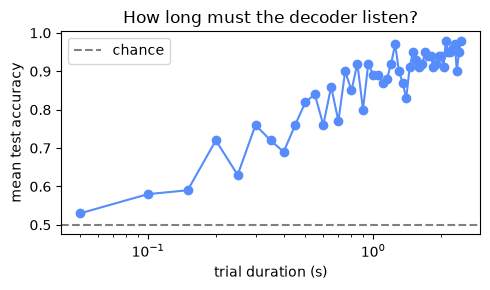

In [31]:
durations = [0.05, 0.1, 0.2, 0.5, 1.0, 2.0]
mean_acc = []

for duration in durations:
    accs = []
    for repeat in range(5):
        X_tr_d, T_tr_d, X_te_d, T_te_d = dataset(duration, rng)
        mu_d = X_tr_d.mean(axis=0)
        sigma_d = X_tr_d.std(axis=0) + 1e-8
        p_d = Perceptron(n_features=5, epochs=50).fit((X_tr_d - mu_d) / sigma_d, T_tr_d)
        accs.append(np.mean(p_d.predict((X_te_d - mu_d) / sigma_d) == T_te_d))
    mean_acc.append(np.mean(accs))
    print(f"{duration:>4} s -> mean test accuracy: {np.mean(accs):.0%}")

plt.figure(figsize=(5, 3))
plt.plot(durations, mean_acc, marker="o")
plt.axhline(0.5, color="gray", linestyle="--", label="chance")
plt.xscale("log")
plt.xlabel("trial duration (s)")
plt.ylabel("mean test accuracy")
plt.title("How long must the decoder listen?")
plt.legend()
plt.tight_layout()
plt.show()

### Solution

1. **Prediction**: neurons 1 and 2 change with the stimulus (1 fires more for B, 2 fires more for A). Neurons 3, 4 and 5 fire at the same rate for A and B: they carry no information.
2. About **95 %** test accuracy (one B trial decoded as A). But look at the mistakes per epoch: they **never reach 0**. Spike counts are noisy, so some A trials look like B trials: the training set is not separable, and the rule runs all 50 epochs.
3. The two largest weights are on **neurons 1 (positive) and 2 (negative)**, as expected. Neurons 3 to 5 get smaller weights, but **not zero**: since the training never converges, the final weights also carry some noise (this is where the pocket of the previous exercise helps).
4. The accuracy climbs with the duration: about chance level at 50 ms, around 70 % at 200 ms, above 90 % from 1 s. A short window holds only a handful of spikes, so the measured rate is very noisy (at 50 ms, one spike more or less changes the rate by 20 Hz).

This is the trade-off of every **brain-computer interface**: listen longer and decode better, or answer faster and make more mistakes. Keep it in mind for Project 1.